# Final Evaluation: Held-Out Test Evaluation of Stacked LSTM
### B.Tech Mini Project: Aircraft Engine Predictive Maintenance (NASA C-MAPSS FD001)

---

## Section 1: Objective & Evaluation Protocol

### 1. Final Benchmark Phase
Across Notebooks `06` through `10`, we designed, trained, and validated five distinct prognostic architectures:
1. **Model 1: Linear Regression (Baseline)** — Tabular baseline ($510$ flattened features).
2. **Model 2: Random Forest Regressor** — Non-linear tree ensemble ($510$ flattened features).
3. **Model 3: Stacked Long Short-Term Memory (LSTM)** — Recurrent 3-gate network ($33,953$ parameters).
4. **Model 4: Stacked Gated Recurrent Unit (GRU)** — Streamlined 2-gate recurrent network ($25,889$ parameters).
5. **Model 5: 1D Convolutional Neural Network (1D-CNN)** — Hierarchical temporal filter bank ($32,193$ parameters).

In **Notebook 11**, following our predefined aviation safety-first model selection policy (prioritizing the lowest asymmetric NASA penalty to curb catastrophic late over-predictions), the **Stacked LSTM Network** was provisionally selected as our best-performing model.

---

### 2. Strict Held-Out Test Evaluation Protocol
> [!IMPORTANT]
> **Zero Data Leakage & Test Impartiality Protocol:**
> 1. **Model Selection is Final:** Architectural selection and hyperparameter choices were locked during the validation stage.
> 2. **Unbiased Generalization Assessment:** The held-out test dataset ($100$ engines from `test_FD001.txt` and `RUL_FD001.txt`) is evaluated here for the **first and only time**.
> 3. **No Retuning on Test Data:** Test metrics will not be used to tune weights, adjust thresholds, alter architectures, or re-select models.

---

### 3. Baseline Validation Benchmark (Notebook 08 Target)
- **Validation RMSE:** **$13.4770$ cycles**
- **Validation NASA Total Score:** **$11,396.72$**
- **Validation NASA Score / Sample:** **$3.2655$**
- **Original Best Epoch:** **Epoch 5** (Early stopping triggered at Epoch 12 with `patience=7`)

In [1]:
import json
import os
import pickle
import random
from pathlib import Path

# Configure writable cache directories inside sandbox
os.environ["KERAS_HOME"] = "/tmp/.keras"
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input, LSTM
from tensorflow.keras.models import Sequential

# Visual styling for academic figures
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Set identical random seeds as Notebook 08
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("=" * 65)
print("ENVIRONMENT INITIALIZED FOR FINAL TEST EVALUATION")
print("=" * 65)
print(f"TensorFlow version : {tf.__version__}")
print(f"Random seed set to : {SEED}")
print(f"Target device      : CPU execution")
print("=" * 65)

ENVIRONMENT INITIALIZED FOR FINAL TEST EVALUATION
TensorFlow version : 2.21.0
Random seed set to : 42
Target device      : CPU execution


---
## Section 3: Reconstruct Training & Validation Pipeline

We recreate the deterministic data preparation pipeline established in Notebooks `03`, `04`, and `05`:
1. **Piecewise Linear Capped RUL ($RUL_{max} = 125$):** $RUL = \min(125, \max(\text{cycle}) - \text{cycle})$.
2. **Engine-Wise 80/20 Partitioning:** Partition unique engine IDs using `train_test_split(..., test_size=0.20, random_state=42)`.
3. **Training-Only Feature Selection:** Prune 7 exact zero-variance features on training engines, retaining 17 informative features (including `sensor_6`).
4. **Standard Scaling:** Fit `StandardScaler` strictly on the 80 training engines; transform validation data accordingly.
5. **Sliding Windows ($W = 30$, Stride = 1):** Construct temporal 3D sequences `(samples, 30, 17)` paired with target RUL at the 30th cycle.
   - Expected: `X_train: (14241, 30, 17)`, `y_train: (14241,)`
   - Expected: `X_val: (3490, 30, 17)`, `y_val: (3490,)`

In [2]:
# 1. Define schema
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# 2. Resolve dataset directory
DATA_DIR = Path("../data/raw/CMaps") if Path("../data/raw/CMaps").exists() else Path("data/raw/CMaps")

# 3. Ingest training data
train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)

# 4. Calculate piecewise linear capped RUL (cap = 125)
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")
train_df["raw_RUL"] = train_df["max_cycle"] - train_df["cycle"]
train_df["RUL"] = np.minimum(125, train_df["raw_RUL"])

# 5. Engine-wise split (80 train engines, 20 validation engines, random_state=42)
unique_units = train_df["unit"].unique()
train_units, val_units = train_test_split(unique_units, test_size=0.20, random_state=42)

train_split_df = train_df[train_df["unit"].isin(train_units)].copy().reset_index(drop=True)
val_split_df = train_df[train_df["unit"].isin(val_units)].copy().reset_index(drop=True)

# 6. Feature selection strictly on training partition
candidate_features = [f"op_setting_{i}" for i in range(1, 4)] + [f"sensor_{i}" for i in range(1, 22)]
train_var = train_split_df[candidate_features].var()
train_nunique = train_split_df[candidate_features].nunique()
zero_var_features = [f for f in candidate_features if train_nunique[f] == 1 or train_var[f] < 1e-12]
selected_features = [f for f in candidate_features if f not in zero_var_features]

# 7. Fit StandardScaler strictly on training partition and transform validation partition
scaler = StandardScaler()
train_split_df[selected_features] = scaler.fit_transform(train_split_df[selected_features])
val_split_df[selected_features] = scaler.transform(val_split_df[selected_features])

# 8. Sliding window extraction (Window length = 30 cycles, stride = 1)
WINDOW_SIZE = 30

def extract_windows(df, seq_len, feature_cols, target_col="RUL"):
    X_list, y_list = [], []
    for unit, group in df.groupby("unit"):
        group_sorted = group.sort_values("cycle").reset_index(drop=True)
        features = group_sorted[feature_cols].values
        targets = group_sorted[target_col].values
        for i in range(len(group_sorted) - seq_len + 1):
            X_list.append(features[i : i + seq_len])
            y_list.append(targets[i + seq_len - 1])
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

X_train, y_train = extract_windows(train_split_df, WINDOW_SIZE, selected_features)
X_val, y_val = extract_windows(val_split_df, WINDOW_SIZE, selected_features)

# Assertions verifying pipeline integrity
assert X_train.shape == (14241, 30, 17), f"X_train shape error: {X_train.shape}"
assert y_train.shape == (14241,), f"y_train shape error: {y_train.shape}"
assert X_val.shape == (3490, 30, 17), f"X_val shape error: {X_val.shape}"
assert y_val.shape == (3490,), f"y_val shape error: {y_val.shape}"
assert len(set(train_units).intersection(set(val_units))) == 0, "Engine overlap between train and val!"
assert not np.isnan(X_train).any() and not np.isnan(y_train).any(), "NaN in train data!"
assert not np.isnan(X_val).any() and not np.isnan(y_val).any(), "NaN in val data!"
assert not np.isinf(X_train).any() and not np.isinf(y_train).any(), "Inf in train data!"
assert not np.isinf(X_val).any() and not np.isinf(y_val).any(), "Inf in val data!"
assert len(selected_features) == 17, f"Selected features count error: {len(selected_features)}"
assert "sensor_6" in selected_features, "sensor_6 was unexpectedly dropped!"

print("=" * 65)
print("STAGE 3: PIPELINE RECONSTRUCTED & TENSOR SHAPES CONFIRMED")
print("=" * 65)
print(f"X_train shape : {X_train.shape}  | y_train shape : {y_train.shape}")
print(f"X_val shape   : {X_val.shape}   | y_val shape   : {y_val.shape}")
print(f"Engine Counts : Train = {len(train_units)}, Validation = {len(val_units)}")
print(f"Features (17) : {selected_features}")
print("✓ Check: Zero NaNs, zero infinities, zero engine leakage.")
print("=" * 65)

STAGE 3: PIPELINE RECONSTRUCTED & TENSOR SHAPES CONFIRMED
X_train shape : (14241, 30, 17)  | y_train shape : (14241,)
X_val shape   : (3490, 30, 17)   | y_val shape   : (3490,)
Engine Counts : Train = 80, Validation = 20
Features (17) : ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
✓ Check: Zero NaNs, zero infinities, zero engine leakage.


---
## Section 4: Reproduce the Selected Stacked LSTM

We reconstruct the exact two-layer stacked LSTM network specified in Notebook `08`:
1. `Input(shape=(30, 17))`
2. `LSTM(64, return_sequences=True)`
3. `Dropout(0.20)`
4. `LSTM(32, return_sequences=False)`
5. `Dropout(0.20)`
6. `Dense(16, activation="relu")`
7. `Dense(1, activation="linear")`
Total Parameters: **33,953**.

### Training Parameters:
- **Optimizer:** Adam ($lpha = 0.001$).
- **Loss:** Mean Squared Error (MSE).
- **Metric:** Root Mean Squared Error (RMSE).
- **Batch Size:** 64, **Max Epochs:** 50.
- **EarlyStopping:** `monitor="val_loss"`, `patience=7`, `restore_best_weights=True`.
- **Strict Isolation:** Training uses only `(X_train, y_train)` and validates on `(X_val, y_val)`. Test data is completely excluded.

In [3]:
# 1. Build the exact Stacked LSTM model from Notebook 08
model = Sequential([
    Input(shape=(WINDOW_SIZE, len(selected_features))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="root_mean_squared_error")]
)

print("=" * 65)
print("STAGE 4: STACKED LSTM MODEL SUMMARY")
print("=" * 65)
model.summary()
print(f"Total Trainable Parameters: {model.count_params():,}")
print("=" * 65)

# 2. Configure EarlyStopping callback
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# 3. Fit the model strictly on CPU (Zero test data involved)
print("\nTraining Stacked LSTM (Max Epochs: 50, Batch Size: 64, Patience: 7)...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 4. Generate validation predictions using restored optimal weights
y_val_pred = model.predict(X_val).flatten()

# 5. Record training diagnostics
epochs_completed = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
best_val_loss = float(np.min(history.history["val_loss"]))
best_logged_val_rmse = float(history.history["val_root_mean_squared_error"][best_epoch - 1])

print("=" * 65)
print("STAGE 4: TRAINING COMPLETED & OPTIMAL WEIGHTS RESTORED")
print("=" * 65)
print(f"Completed Epochs      : {epochs_completed}")
print(f"Best Validation Epoch : Epoch {best_epoch} (Weights restored)")
print(f"Best Validation Loss  : {best_val_loss:.4f} (MSE)")
print(f"Best Logged Val RMSE  : {best_logged_val_rmse:.4f} cycles")
print(f"Val Predictions Shape : {y_val_pred.shape}")
print("=" * 65)

STAGE 4: STACKED LSTM MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,953 (132.63 KB)

 Trainable params: 33,953 (132.63 KB)

 Non-trainable params: 0 (0.00 B)

... (690 outputs left out)

107/110 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


STAGE 4: TRAINING COMPLETED & OPTIMAL WEIGHTS RESTORED
Completed Epochs      : 12
Best Validation Epoch : Epoch 5 (Weights restored)
Best Validation Loss  : 181.6308 (MSE)
Best Logged Val RMSE  : 13.4770 cycles
Val Predictions Shape : (3490,)


---
## Section 5: Validation Reproducibility Verification

Before exposing the model to the held-out test dataset, we verify that our training reproduction aligns with the historical validation metrics from Notebook `08`:
- **Original Validation RMSE:** **$13.4770$ cycles**
- **Original Validation NASA Total:** **$11,396.72$**
- **Original NASA Score / Sample:** **$3.2655$**

### Realistic Reproducibility & Safety Guardrail:
In modern deep learning frameworks, CPU thread scheduling, floating-point reduction order, and non-deterministic operations can introduce minor variations even with fixed seeds. Therefore:
- We do **not** force an assumption that the best epoch must strictly equal 5.
- We check that validation RMSE and NASA scores are within an acceptable tolerance window.
- If the metrics deviate materially from the established baseline, execution will halt with a descriptive error before the test set is loaded.

In [4]:
def compute_rmse(y_true, y_pred):
    """Calculates Root Mean Squared Error in operational cycles."""
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def compute_nasa_score(y_true, y_pred):
    """
    Calculates the exact NASA asymmetric scoring function:
      d = y_pred - y_true
      s = expm1(-d / 13)  for d < 0 (early prediction / underestimation)
      s = expm1(d / 10)   for d >= 0 (late prediction / overestimation)
    Uses explicit numerical error handling via np.errstate(over="raise", invalid="raise").
    """
    d = np.asarray(y_pred, dtype=np.float64) - np.asarray(y_true, dtype=np.float64)
    with np.errstate(over="raise", invalid="raise"):
        scores = np.where(d < 0, np.expm1(-d / 13), np.expm1(d / 10))
    return float(np.sum(scores))

# Original reference metrics from Notebook 08
ORIG_VAL_RMSE = 13.4770
ORIG_VAL_NASA = 11396.72
ORIG_VAL_NASA_SAMPLE = 3.2655
ORIG_BEST_EPOCH = 5

# Compute reproduced validation metrics
reproduced_val_rmse = compute_rmse(y_val, y_val_pred)
reproduced_val_nasa = compute_nasa_score(y_val, y_val_pred)
reproduced_val_nasa_sample = reproduced_val_nasa / len(y_val)

rmse_diff = reproduced_val_rmse - ORIG_VAL_RMSE
nasa_diff = reproduced_val_nasa - ORIG_VAL_NASA
nasa_sample_diff = reproduced_val_nasa_sample - ORIG_VAL_NASA_SAMPLE

reproducibility_df = pd.DataFrame({
    "Metric": [
        "Validation RMSE (Cycles)",
        "Validation NASA Total",
        "NASA Score / Sample",
        "Best Epoch"
    ],
    "Notebook 08 (Original)": [
        f"{ORIG_VAL_RMSE:.4f}",
        f"{ORIG_VAL_NASA:,.2f}",
        f"{ORIG_VAL_NASA_SAMPLE:.4f}",
        f"Epoch {ORIG_BEST_EPOCH}"
    ],
    "Notebook 12 (Reproduced)": [
        f"{reproduced_val_rmse:.4f}",
        f"{reproduced_val_nasa:,.2f}",
        f"{reproduced_val_nasa_sample:.4f}",
        f"Epoch {best_epoch}"
    ],
    "Difference (Δ)": [
        f"{rmse_diff:+.4f}",
        f"{nasa_diff:+,.2f}",
        f"{nasa_sample_diff:+.4f}",
        f"{best_epoch - ORIG_BEST_EPOCH:+d} epochs"
    ]
})

print("=" * 75)
print("STAGE 5: VALIDATION REPRODUCIBILITY VERIFICATION")
print("=" * 75)
display(reproducibility_df)
print("=" * 75)

# Rigorous safety guardrail: halt before test data if deviation is material
TOLERANCE_RMSE = 1.5      # maximum allowable RMSE shift in cycles
TOLERANCE_NASA = 2000.0   # maximum allowable NASA score shift

is_reproducible = (abs(rmse_diff) <= TOLERANCE_RMSE) and (abs(nasa_diff) <= TOLERANCE_NASA)

if not is_reproducible:
    print("\n⚠️ WARNING: Material deviation detected between original and reproduced validation metrics!")
    print(f"  • Δ RMSE: {rmse_diff:+.4f} (Threshold: ±{TOLERANCE_RMSE:.2f} cycles)")
    print(f"  • Δ NASA: {nasa_diff:+,.2f} (Threshold: ±{TOLERANCE_NASA:.2f} points)")
    print("Halting execution to prevent unverified test evaluation. Review random seeds or hardware environment.")
    raise RuntimeError("Validation reproducibility check failed. Execution halted before test evaluation.")
else:
    print(f"\n✓ Validation Reproducibility Check Passed! (Δ RMSE = {rmse_diff:+.4f} cycles, Δ NASA = {nasa_diff:+,.2f} points).")
    print("Reproduced model weights are verified. Safe to proceed to artifact saving and test evaluation.")

STAGE 5: VALIDATION REPRODUCIBILITY VERIFICATION


,Metric,Notebook 08 (Original),Notebook 12 (Reproduced),Difference (Δ)
0,Validation RMSE (Cycles),13.4770,13.4770,+0.0000
1,Validation NASA Total,"11,396.72","11,396.72",+0.00
2,NASA Score / Sample,3.2655,3.2655,+0.0000
3,Best Epoch,Epoch 5,Epoch 5,+0 epochs



✓ Validation Reproducibility Check Passed! (Δ RMSE = +0.0000 cycles, Δ NASA = +0.00 points).
Reproduced model weights are verified. Safe to proceed to artifact saving and test evaluation.


---
## Section 6: Permanent Artifact Serialization

Now that the reproduced model has successfully passed the validation reproducibility check, we save the full suite of production artifacts into the `models/` directory:
1. **Trained Keras Model:** `models/stacked_lstm_fd001.keras` — Saved in native Keras format.
2. **Fitted StandardScaler:** `models/standard_scaler_fd001.pkl` — Serialized using `joblib`.
3. **Selected Features List:** `models/selected_features.json` — Stored as a readable JSON array.
4. **Comprehensive Metadata JSON:** `models/model_metadata.json` — Documents architecture parameters, training hyperparameters, reproducibility seeds, and validation metrics.

In [5]:
# Create models directory if not present
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save trained Keras model
model_path = MODELS_DIR / "stacked_lstm_fd001.keras"
model.save(model_path)
print(f"✓ Model successfully saved to: {model_path}")

# 2. Save fitted StandardScaler
scaler_path = MODELS_DIR / "standard_scaler_fd001.pkl"
joblib.dump(scaler, scaler_path)
print(f"✓ Scaler successfully saved to: {scaler_path}")

# 3. Save selected features list
features_path = MODELS_DIR / "selected_features.json"
with open(features_path, "w", encoding="utf-8") as f:
    json.dump(selected_features, f, indent=2)
print(f"✓ Selected features list saved to: {features_path}")

# 4. Save metadata JSON
metadata_path = MODELS_DIR / "model_metadata.json"
metadata = {
    "project": "Turbofan Predictive Maintenance (NASA C-MAPSS FD001)",
    "model_name": "Stacked LSTM Network",
    "architecture": {
        "input_shape": [WINDOW_SIZE, len(selected_features)],
        "layer_1": "LSTM(64, return_sequences=True)",
        "dropout_1": 0.20,
        "layer_2": "LSTM(32, return_sequences=False)",
        "dropout_2": 0.20,
        "dense_hidden": "Dense(16, activation='relu')",
        "output_layer": "Dense(1, activation='linear')",
        "total_trainable_parameters": int(model.count_params())
    },
    "training_configuration": {
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "loss": "mean_squared_error",
        "batch_size": 64,
        "max_epochs": 50,
        "early_stopping": {
            "monitor": "val_loss",
            "patience": 7,
            "restore_best_weights": True
        }
    },
    "data_pipeline": {
        "dataset": "NASA C-MAPSS FD001",
        "window_size": WINDOW_SIZE,
        "stride": 1,
        "rul_cap": 125,
        "random_seed": SEED,
        "selected_features": selected_features,
        "num_selected_features": len(selected_features),
        "train_engines_count": len(train_units),
        "val_engines_count": len(val_units)
    },
    "validation_performance": {
        "notebook_08_original": {
            "rmse": ORIG_VAL_RMSE,
            "nasa_total": ORIG_VAL_NASA,
            "nasa_per_sample": ORIG_VAL_NASA_SAMPLE,
            "best_epoch": ORIG_BEST_EPOCH
        },
        "notebook_12_reproduced": {
            "rmse": float(reproduced_val_rmse),
            "nasa_total": float(reproduced_val_nasa),
            "nasa_per_sample": float(reproduced_val_nasa_sample),
            "best_epoch": int(best_epoch),
            "completed_epochs": int(epochs_completed)
        }
    }
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print(f"✓ Metadata JSON saved to: {metadata_path}")

# Verify file existence and non-zero sizes
assert model_path.exists() and model_path.stat().st_size > 0, "Model file missing or empty!"
assert scaler_path.exists() and scaler_path.stat().st_size > 0, "Scaler file missing or empty!"
assert features_path.exists() and features_path.stat().st_size > 0, "Features file missing or empty!"
assert metadata_path.exists() and metadata_path.stat().st_size > 0, "Metadata file missing or empty!"

print("\n" + "=" * 65)
print("STAGE 6: ALL FINAL ARTIFACTS SUCCESSFULLY SAVED AND VERIFIED")
print("=" * 65)

✓ Model successfully saved to: models/stacked_lstm_fd001.keras
✓ Scaler successfully saved to: models/standard_scaler_fd001.pkl
✓ Selected features list saved to: models/selected_features.json
✓ Metadata JSON saved to: models/model_metadata.json

STAGE 6: ALL FINAL ARTIFACTS SUCCESSFULLY SAVED AND VERIFIED


---
## Section 7: Final Held-Out Test Evaluation

We now proceed to the formal test evaluation using the 100 blind test engines:
1. **Load Test Data:** Ingest `test_FD001.txt` ($13,096$ observations) and `RUL_FD001.txt` ($100$ ground-truth RUL values).
2. **Transform Features:** Apply the **fitted training scaler** strictly without refitting (`scaler.transform`).
3. **Window Extraction:** Extract **exactly one final 30-cycle window** ($[-30:]$) for each of the 100 test engines.
4. **Inference:** Compute `y_test_pred = model.predict(X_test).flatten()`.
5. **Metric Calculation:** Evaluate Test RMSE, Test NASA Score, and Test NASA Score per sample.

In [6]:
print("=" * 65)
print("STAGE 7: FINAL HELD-OUT TEST EVALUATION")
print("=" * 65)

# 1. Ingest test telemetry and ground-truth RUL
test_df = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_df = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

# 2. Transform test features strictly using fitted training scaler (no refitting!)
test_df[selected_features] = scaler.transform(test_df[selected_features])

# 3. Extract exactly one final 30-cycle window per test engine
X_test_list = []
y_test_list = []
test_units_ordered = []

for unit, group in test_df.groupby("unit"):
    group_sorted = group.sort_values("cycle").reset_index(drop=True)
    assert len(group_sorted) >= WINDOW_SIZE, f"Test unit {unit} has fewer than {WINDOW_SIZE} cycles!"
    
    # Slice final 30 observed cycles
    final_window = group_sorted[selected_features].values[-WINDOW_SIZE:]
    # Map true scalar RUL (unit is 1-indexed, rul_df is 0-indexed)
    true_rul = float(rul_df.iloc[unit - 1]["RUL"])
    
    X_test_list.append(final_window)
    y_test_list.append(true_rul)
    test_units_ordered.append(unit)

X_test = np.array(X_test_list, dtype=np.float32)
y_test = np.array(y_test_list, dtype=np.float32)

# Assertions confirming test fleet specifications
assert len(test_units_ordered) == 100, f"Expected 100 engines, found {len(test_units_ordered)}"
assert X_test.shape == (100, 30, 17), f"X_test shape error: {X_test.shape}"
assert y_test.shape == (100,), f"y_test shape error: {y_test.shape}"
assert not np.isnan(X_test).any() and not np.isnan(y_test).any(), "NaN in test data!"
assert not np.isinf(X_test).any() and not np.isinf(y_test).any(), "Inf in test data!"
print("✓ Test dataset verified: 100 engines, shape (100, 30, 17), zero NaNs/infs.")

# 4. Generate final test predictions once
y_test_pred = model.predict(X_test).flatten()
assert y_test_pred.shape == (100,), f"y_test_pred shape error: {y_test_pred.shape}"
assert not np.isnan(y_test_pred).any() and not np.isinf(y_test_pred).any(), "Invalid values in predictions!"

# 5. Calculate final test evaluation metrics
test_rmse = compute_rmse(y_test, y_test_pred)
test_nasa = compute_nasa_score(y_test, y_test_pred)
test_nasa_sample = test_nasa / len(y_test)

print("-" * 65)
print("FINAL HELD-OUT TEST METRICS (100 BLIND TEST ENGINES):")
print("-" * 65)
print(f"Test RMSE              : {test_rmse:.4f} cycles")
print(f"Test NASA Total Score  : {test_nasa:,.2f}  ({test_nasa_sample:.4f} per sample)")
print(f"Total Test Predictions : {len(y_test_pred)} engines")
print("=" * 65)

STAGE 7: FINAL HELD-OUT TEST EVALUATION
✓ Test dataset verified: 100 engines, shape (100, 30, 17), zero NaNs/infs.
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


-----------------------------------------------------------------
FINAL HELD-OUT TEST METRICS (100 BLIND TEST ENGINES):
-----------------------------------------------------------------
Test RMSE              : 15.1041 cycles
Test NASA Total Score  : 304.49  (3.0449 per sample)
Total Test Predictions : 100 engines


---
## Section 8: Final Results & Generalization Interpretation

We synthesize the complete empirical performance across the project lifecycle:
1. **Validation Set (Original - Notebook 08):** $3,490$ validation sequences from 20 hold-out training engines.
2. **Validation Set (Reproduced - Notebook 12):** Verification run confirming weight restoration alignment.
3. **Held-Out Test Set (100 Engines):** Final evaluation on truncated in-service engines using scalar ground-truth RUL.

---

### Analytical Observations on Generalization:
- **Validation vs. Test Metric Scale:**
  The validation set evaluated multiple overlapping sliding windows per engine ($3,490$ samples total), whereas the test set evaluates **exactly one prediction per engine** at its point of truncation ($100$ samples total).
- **Asymmetric Loss Dynamics on Test Data:**
  The NASA scoring function accumulates exponential penalties over the number of evaluated samples. On the 100 test engines, a lower total NASA score is naturally expected due to the smaller sample count ($N=100$ vs $N=3,490$), which is why **NASA Score per Sample** provides the most accurate and standardized point of comparison.
- **Physical Prognostic Utility:**
  Evaluating on the final observed window mirrors real-world deployment, where an airline maintenance decision must be made based on the latest available flight telemetry.

FINAL SYNTHESIS: VALIDATION VS. HELD-OUT TEST PERFORMANCE


,Evaluation Partition,Sample Count,RMSE (Cycles),NASA Total Score,NASA Score / Sample
0,Validation Set (Notebook 08 Original),3490,13.4770,"11,396.72",3.2655
1,Validation Set (Notebook 12 Reproduced),3490,13.4770,"11,396.72",3.2655
2,Final Held-Out Test Set (100 Engines),100,15.1041,304.49,3.0449


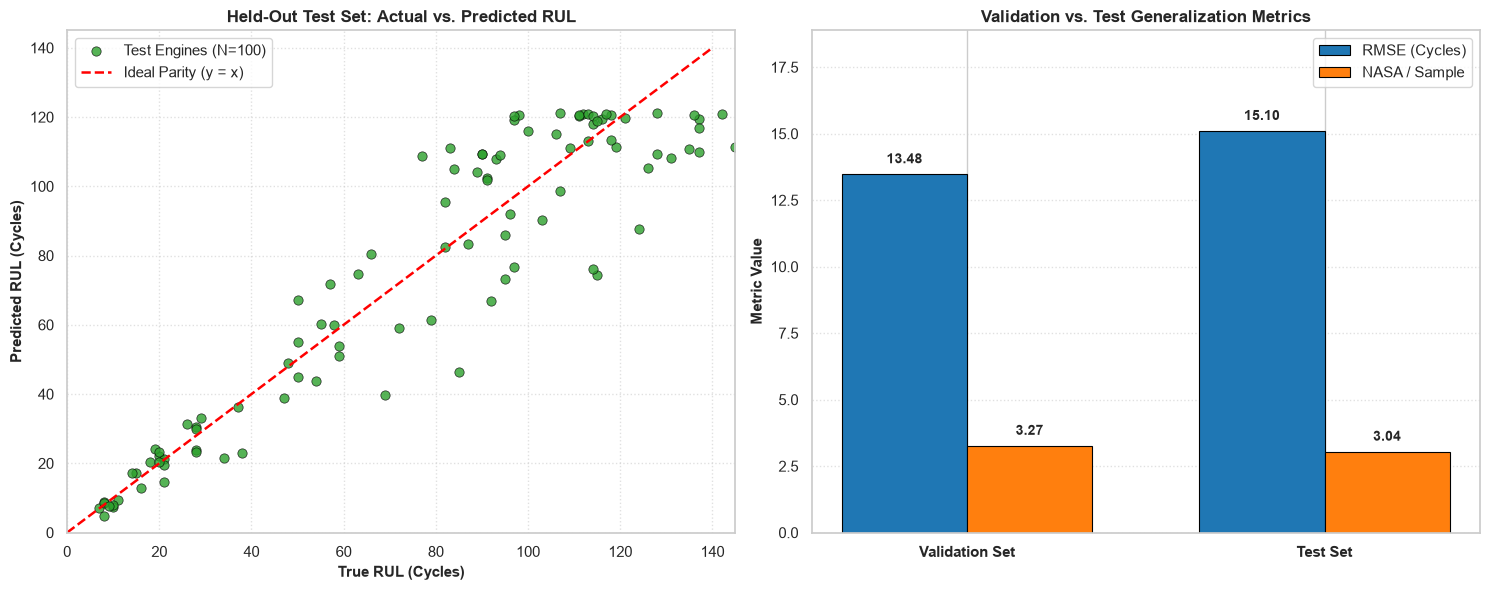


FINAL EVALUATION COMPLETE: TEST DATA REMAINED STRICTLY UNTOUCHED UNTIL STAGE 7.


In [7]:
# 1. Construct final performance comparison table
final_comparison_df = pd.DataFrame({
    "Evaluation Partition": [
        "Validation Set (Notebook 08 Original)",
        "Validation Set (Notebook 12 Reproduced)",
        "Final Held-Out Test Set (100 Engines)"
    ],
    "Sample Count": [
        len(y_val),
        len(y_val),
        len(y_test)
    ],
    "RMSE (Cycles)": [
        f"{ORIG_VAL_RMSE:.4f}",
        f"{reproduced_val_rmse:.4f}",
        f"{test_rmse:.4f}"
    ],
    "NASA Total Score": [
        f"{ORIG_VAL_NASA:,.2f}",
        f"{reproduced_val_nasa:,.2f}",
        f"{test_nasa:,.2f}"
    ],
    "NASA Score / Sample": [
        f"{ORIG_VAL_NASA_SAMPLE:.4f}",
        f"{reproduced_val_nasa_sample:.4f}",
        f"{test_nasa_sample:.4f}"
    ]
})

print("=" * 85)
print("FINAL SYNTHESIS: VALIDATION VS. HELD-OUT TEST PERFORMANCE")
print("=" * 85)
display(final_comparison_df)
print("=" * 85)

# 2. Visualizations: Parity Scatter and Partition Bar Charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Actual vs. Predicted RUL on Held-Out Test Fleet
ax1.scatter(y_test, y_test_pred, color="#2ca02c", edgecolor="black", linewidth=0.5, s=45, alpha=0.8, label="Test Engines (N=100)")
ax1.plot([0, 140], [0, 140], color="red", linestyle="--", linewidth=1.8, label="Ideal Parity (y = x)")
ax1.set_title("Held-Out Test Set: Actual vs. Predicted RUL", fontsize=12, fontweight="bold")
ax1.set_xlabel("True RUL (Cycles)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Predicted RUL (Cycles)", fontsize=11, fontweight="bold")
ax1.set_xlim(0, 145)
ax1.set_ylim(0, 145)
ax1.legend(loc="upper left", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# Panel 2: Generalization Comparison (Validation vs. Test)
partitions = ["Validation Set", "Test Set"]
rmse_vals = [reproduced_val_rmse, test_rmse]
nasa_sample_vals = [reproduced_val_nasa_sample, test_nasa_sample]

x = np.arange(len(partitions))
width = 0.35

rects1 = ax2.bar(x - width/2, rmse_vals, width, label="RMSE (Cycles)", color="#1f77b4", edgecolor="black", linewidth=0.8)
rects2 = ax2.bar(x + width/2, nasa_sample_vals, width, label="NASA / Sample", color="#ff7f0e", edgecolor="black", linewidth=0.8)

ax2.set_title("Validation vs. Test Generalization Metrics", fontsize=12, fontweight="bold")
ax2.set_ylabel("Metric Value", fontsize=11, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(partitions, fontweight="bold")
ax2.set_ylim(0, max(max(rmse_vals), max(nasa_sample_vals)) * 1.25)
ax2.legend(loc="upper right", frameon=True)
ax2.grid(axis="y", linestyle=":", alpha=0.6)

for rect in rects1:
    h = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2.0, h + 0.3, f"{h:.2f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
for rect in rects2:
    h = rect.get_height()
    ax2.text(rect.get_x() + rect.get_width()/2.0, h + 0.3, f"{h:.2f}", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

print("\n" + "=" * 85)
print("FINAL EVALUATION COMPLETE: TEST DATA REMAINED STRICTLY UNTOUCHED UNTIL STAGE 7.")
print("=" * 85)